# Comparativa de detectores faciales

En este cuaderno auxiliar se comparan los siguientes detectores faciales, con el fin de elegir aquel que proporcione unos mejores resultados, para ser usado en [`prac5.ipynb`](prac5.ipynb):

- **Viola-Jones**: detector clásico, muy rápido pero con limitaciones como la orientación de las caras.
- **DNN ResNet-10**: detector de rendimiento medio, formado por una red neuronal con ResNet-10 como base.
- **MTCNN**: detector con redes neuronales combinadas para devolver 5 _landmarks_ de la cara.
- **BlazeFace**: detector de caras de MediaPipe.
- **YuNet**, detector de caras incluido en OpenCV, que promete un buen trade-off entre eficiencia y acierto.
- **RetinaFace**: detector muy preciso, pero lento y pesado.

Los prototipos deben ser rápidos y robustos, pues se usan con la _webcam_ en tiempo real. Además, conociendo la naturaleza de la demostración a realizar (pipa), también se valorarán positivamente los detectores que permitan reconocer la posición de la boca.

## 1. Preparación

In [1]:
import json
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common.benchmark import save_system_info
from common.experiment import DETECTOR_RESULTS
from common.faces.detectors import DETECTORS, draw_faces
from common.faces.metrics import best_f1_threshold, evaluate
from common.faces.widerface import build_subset, download_widerface, load_image

Parámetros de la comparativa:

- `WIDTH`: ancho al que se escalan las imágenes (adaptado a la _webcam_, 640 × 480).
- `MIN_FACE`: altura mínima, en píxeles, de todas las caras de cada imagen elegida.
- `N_IMAGES`, `MAX_FACES` y `SEED`: con el fin de realizar experimentos reproducibles, configuración de la elección aleatoria de imágenes para evaluar los detectores.
- `WARMUP`: número de imágenes de calentamiento, que se procesan antes de medir tiempos.
- `MAX_MS`: _timeout_ de espera para una respuesta del detector.
- `FORCE`: si es `False`, se reutilizan las detecciones guardadas.

In [2]:
WIDTH = 640
MIN_FACE = 40
N_IMAGES = 1000
MAX_FACES = 10
SEED = 0
WARMUP = 10
MAX_MS = 20
FORCE = False

DETS = DETECTOR_RESULTS / "dets"
DETS.mkdir(parents=True, exist_ok=True)
LABELS = {name: detector.label for name, detector in DETECTORS.items()}
COLORS = {"vj": "#2a78d6", "dnn": "#eb6834", "mtcnn": "#1baf7a", 
          "blazeface": "#eda100", "yunet": "#e87ba4", "retinaface": "#008300"}


def hex_to_bgr(color):
    return tuple(int(color[i:i + 2], 16) for i in (5, 3, 1))

Los tiempos dependen del equipo, por lo que se guarda su información. Todos los detectores se ejecutan en la CPU.

In [3]:
save_system_info(DETECTOR_RESULTS / "system_info.json",
                 ["opencv-contrib-python", "mediapipe", "mtcnn", "tensorflow", "retina-face"])

{'os': 'Windows-10-10.0.26300-SP0',
 'cpu': 'AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD',
 'cpu_cores': 8,
 'ram_gb': 34.0,
 'python': '3.11.18',
 'packages': {'opencv-contrib-python': '4.12.0.88',
  'mediapipe': '1.2.3',
  'mtcnn': '1.0.0',
  'tensorflow': '2.21.0',
  'retina-face': '0.0.19'}}

## 2. Conjunto de datos

Se utiliza la validación de [WIDER FACE](http://shuoyang1213.me/WIDERFACE/), el conjunto de referencia en detección facial: 3,226 imágenes con todas sus caras anotadas (una caja por cara).

De ahí se eligen al azar 1,000 imágenes que cumplan:

- Tener entre 1 y 10 caras, pues no buscamos detecciones en escenas multitudinarias.
- Que todas las caras midan al menos 40 píxeles de alto, para coincidir con el umbral fijado.
- Que ninguna cara esté marcada como inválida.

Así, todas las caras de las imágenes están anotadas y son suficientemente grandes, de forma que se puedan comparar correctamente las distintas detecciones.

Las imágenes se leen directamente desde el `zip` del _dataset_.

In [4]:
download_widerface()
samples = build_subset(WIDTH, MIN_FACE, N_IMAGES, MAX_FACES, SEED)
print(f"{len(samples)} imágenes y {sum(len(s.boxes) for s in samples)} caras")

1000 imágenes y 1860 caras


Por ejemplo, estas son algunas de las imágenes del conjunto de datos:

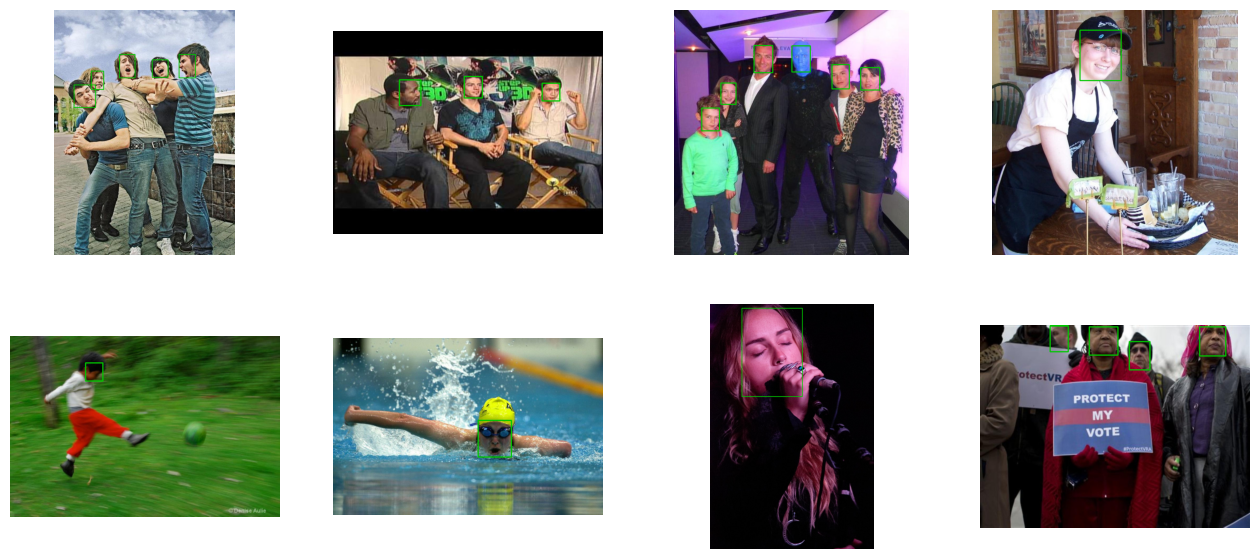

In [5]:
plt.figure(figsize=(16, 7))
for i, sample in enumerate(samples[::125]):
    image = load_image(sample)
    for x1, y1, x2, y2 in sample.boxes.astype(int):
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 200, 0), 2)
    plt.subplot(2, 4, i + 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.axis("off")
plt.show()

## 3. Detectores

Como se ha indicado ya en apartados anteriores, los detectores a estudiar son:

- **Viola-Jones** (2001): cascada de clasificadores Haar. Sin _landmarks_. **Umbral por defecto = 5 vecinos**.
- **DNN ResNet-10** (2017): red neuronal con ResNet-10. Sin _landmarks_. **Umbral por defecto = 0.5**.
- **MTCNN** (2016): cascada de tres redes convolucionales. 5 _landmarks_ (ojos, nariz y comisuras). **Umbral por defecto = 0.8**.
- **BlazeFace** (2019): red ligera diseñada para dispositivos como teléfonos móviles. 6 _landmarks_ (ojos, nariz, boca y orejas). **Umbral por defecto: 0.5**.
- **YuNet** (2023): red muy ligera, diseñada también para dispositivos pequeños y tiempo real. 5 _landmarks_ (ojos, nariz y comisuras). **Umbral por defecto: 0.9**.
- **RetinaFace** (2019): red pesada pero muy precisa, que usa ResNet-50. 5 _landmarks_ (ojos, nariz y comisuras). **Umbral por defecto: 0.9**.

Con el fin de uniformizar la interacción con los distintos detectores, se ha implementado una misma interfaz para todos ellos ([`faces/detectors.py`](common/faces/detectors.py)). Cada uno recibe una imagen BGR y devuelve una lista de caras detectadas (`Face`), junto con parámetros como la confianza y los _landmarks_.

## 4. Métricas

Las métricas utilizadas se recogen en [`faces/metrics.py`](common/faces/metrics.py). Como es habitual en este tipo de problemas, las detecciones se eligen por confianza e IoU, con umbral de 0.5 en este último. Habiendo hallado verdaderos positivos, falsos positivos, verdaderos negativos y falsos negativos, se calculan las métricas. En este caso, **precisión**, **exhaustividad**, **F1**, **AP@50** y el **tiempo de ejecución** (llamada al detector sin contar la lectura de la imagen).

## 5. Ejecución

`run_detector` ejecuta un detector sobre todas las imágenes y guarda sus detecciones y tiempos en `results/face_detectors/dets/`:

In [6]:
def run_detector(name):
    path = DETS / f"{name}.json"
    if path.exists() and not FORCE:
        return json.load(open(path))

    detector = DETECTORS[name]()
    for sample in samples[:WARMUP]:
        detector(load_image(sample), detector.min_score)

    dets, times = [], []
    for sample in samples:
        image = load_image(sample)
        start = time.perf_counter()
        faces = detector(image, detector.min_score)
        times.append((time.perf_counter() - start) * 1000)
        dets.append([[float(v) for v in list(face.box) + [face.score]] for face in faces])
    detector.close()
    print(f"{LABELS[name]}: {len(samples)} imágenes")

    result = {"dets": dets, "ms": times}
    json.dump(result, open(path, "w"))
    return result


runs = {name: run_detector(name) for name in DETECTORS}

## 6. Evaluación

### 6.1 Umbral de confianza

A diferencia de otro tipo de detecciones, en este caso, el umbral de confianza se decide de forma independiente para cada detector. Cada detector indica un valor recomendado para este umbral, pues internamente este da lugar a distintos efectos en el comportamiento del detector. Para evaluar todos los detectores de forma justa, se han comprobado distintos valores de umbrales, y escogido aquel que proporciona mejores métricas (F1) para ese detector.

Además, para diferenciar las imágenes de calibración (`CALIB`) de las imágenes de evaluación (`TEST`), se realiza una división 50/50 del conjunto original de imágenes.

In [7]:
CALIB, TEST = list(range(0, len(samples), 2)), list(range(1, len(samples), 2))


def evaluate_on(name, indices, threshold):
    return evaluate([runs[name]["dets"][i] for i in indices], [samples[i] for i in indices], threshold)


thresholds = {name: best_f1_threshold(evaluate_on(name, CALIB, detector.threshold))
              for name, detector in DETECTORS.items()}

### 6.2 Resultados

Estos son los resultados proporcionados por cada detector sobre el subconjunto de WiderFace escogido:

In [8]:
rows = {}
for name, detector in DETECTORS.items():
    default, tuned = evaluate_on(name, TEST, detector.threshold), evaluate_on(name, TEST, thresholds[name])
    rows[name] = {"Detector": detector.label, "AP@50": tuned["ap"], "F1 (umbral por defecto)": default["f1"],
                  "Umbral ajustado": thresholds[name], "Precision": tuned["precision"], "Recall": tuned["recall"],
                  "F1": tuned["f1"], "FP por imagen": tuned["fp_per_image"],
                  "ms por imagen": np.median(runs[name]["ms"]), "Boca": detector.has_mouth}

summary = pd.DataFrame.from_dict(rows, orient="index")
summary.to_csv(DETECTOR_RESULTS / "summary.csv", index=False)
summary.style.hide(axis="index").format(precision=3)

Detector,AP@50,F1 (umbral por defecto),Umbral ajustado,Precision,Recall,F1,FP por imagen,ms por imagen,Boca
Viola-Jones,0.546,0.586,9.000,0.837,0.483,0.613,0.176,8.427,False
DNN ResNet-10,0.855,0.842,0.349,0.895,0.808,0.850,0.176,10.043,False
MTCNN,0.865,0.880,0.929,0.981,0.815,0.890,0.030,90.288,True
BlazeFace,0.352,0.475,0.629,0.845,0.332,0.477,0.114,1.360,True
YuNet,0.941,0.779,0.772,0.974,0.885,0.928,0.044,8.770,True
RetinaFace,0.974,0.964,0.969,0.979,0.950,0.964,0.038,577.775,True


### 6.3 Curvas precisión-exhaustividad

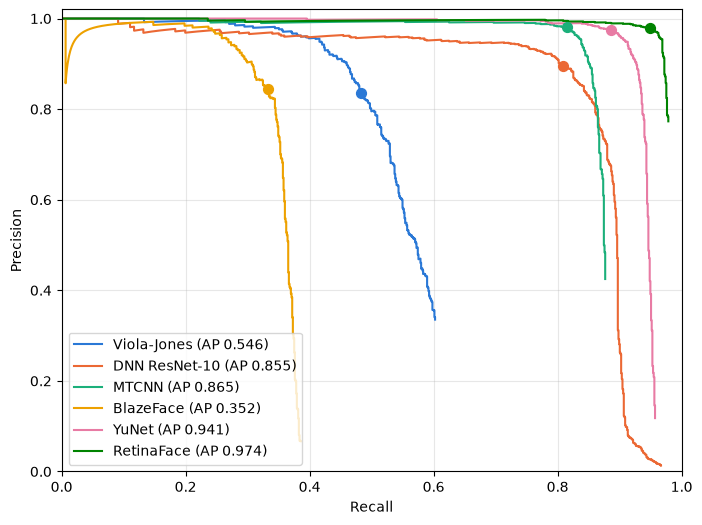

In [9]:
plt.figure(figsize=(8, 6))
for name in DETECTORS:
    recall, precision, _ = evaluate_on(name, TEST, thresholds[name])["curve"]
    plt.plot(recall, precision, color=COLORS[name], label=f"{LABELS[name]} (AP {summary.loc[name, 'AP@50']:.3f})")
    plt.scatter(summary.loc[name, "Recall"], summary.loc[name, "Precision"], color=COLORS[name], s=50, zorder=3)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend(loc="lower left")
plt.savefig(DETECTOR_RESULTS / "pr_curves.png", dpi=120, bbox_inches="tight")
plt.show()

### 6.4 Velocidad frente a precisión

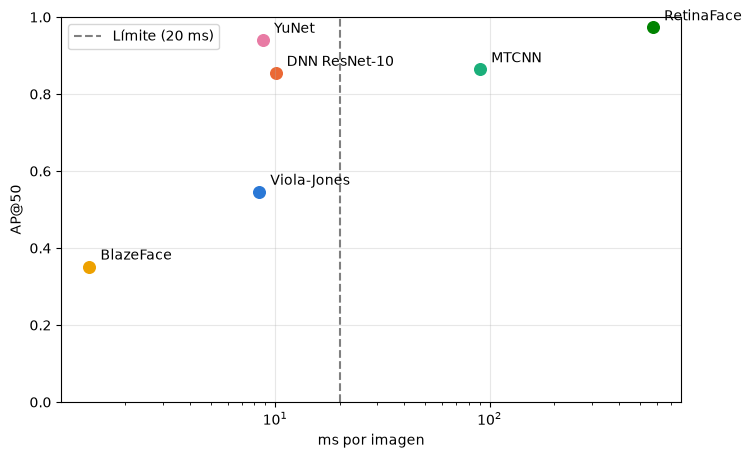

In [10]:
plt.figure(figsize=(8, 5))
for name in DETECTORS:
    x, y = summary.loc[name, "ms por imagen"], summary.loc[name, "AP@50"]
    plt.scatter(x, y, color=COLORS[name], s=70)
    plt.annotate(LABELS[name], (x, y), xytext=(8, 5), textcoords="offset points")
plt.axvline(MAX_MS, color="gray", linestyle="--", label=f"Límite ({MAX_MS} ms)")
plt.xscale("log")
plt.xlabel("ms por imagen")
plt.ylabel("AP@50")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 7. Conclusiones

El detector escogido debe permitir su uso en tiempo real (procesamiento de unos 30 fotogramas por segundo) y debe conocer la posición de la boca, para poderla utilizar en el filtro.

Solo YuNet y BlazeFace cumplen ambos requisitos. Entre estos ds, YuNet tiene el mayor AP@50. Es por este motivo que se escoge YuNet como detector de caras de la aplicación. Se utiliza el umbral de 0.77 ajustado en este cuaderno.

Esta red tiene unos resultados muy cercanos al modelo de referencia para este tipo de problemas (RetinaFace), sin comprometer el tiempo de ejecución. Se ejecuta unas 65 veces más rápido que este último.

Se destaca también la importancia de calibrar correctamente el umbral, pues de lo contrario los resultados se ven considerablemente afectados.